Original dataset:
   Rubber_Content (%)  10 kPa  40 kPa  70 kPa
0                   0     155     350     525
1                  10     135     295     410
2                  20     115     255     355
3                  30      82     250     350
4                  40      75     220     315

Missing values:
Rubber_Content (%)            0
Confining Pressure            0
Peak Deviator Stress (kPa)    0
dtype: int64

Processed dataset:
    Rubber_Content (%) Confining Pressure  Peak Deviator Stress (kPa)
0                    0             10 kPa                         155
1                   10             10 kPa                         135
2                   20             10 kPa                         115
3                   30             10 kPa                          82
4                   40             10 kPa                          75
5                    0             40 kPa                         350
6                   10             40 kPa                         295


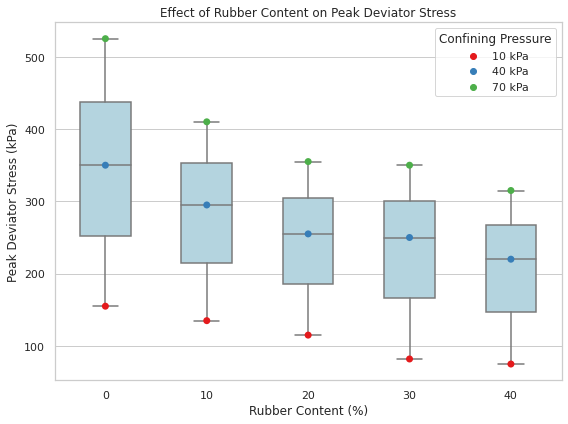


Data visualisation completed successfully.


In [1]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Approximate RGM experimental data
# Digitised from published figures
data = {
    'Rubber_Content (%)': [0, 10, 20, 30, 40],
    '10 kPa': [155, 135, 115, 82, 75],
    '40 kPa': [350, 295, 255, 250, 220],
    '70 kPa': [525, 410, 355, 350, 315]
}

# 2. Create a Pandas DataFrame
df = pd.DataFrame(data)

print("Original dataset:")
print(df)

# 3. Reshape data using Pandas
df_long = df.melt(
    id_vars='Rubber_Content (%)',
    var_name='Confining Pressure',
    value_name='Peak Deviator Stress (kPa)'
)

# 4. Check and handle missing values
print("\nMissing values:")
print(df_long.isnull().sum())

df_long = df_long.dropna()

# 5. Display processed data
print("\nProcessed dataset:")
print(df_long)

# 6. Create boxplot
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(8, 6))

sns.boxplot(
    data=df_long,
    x='Rubber_Content (%)',
    y='Peak Deviator Stress (kPa)',
    color='lightblue',
    width=0.5,
    ax=ax
)

# 7. Add individual data points
sns.stripplot(
    data=df_long,
    x='Rubber_Content (%)',
    y='Peak Deviator Stress (kPa)',
    hue='Confining Pressure',
    palette='Set1',
    size=7,
    jitter=False,
    ax=ax
)

# 8. Customise figure
ax.set_xlabel('Rubber Content (%)')
ax.set_ylabel('Peak Deviator Stress (kPa)')
ax.set_title(
    'Effect of Rubber Content on Peak Deviator Stress'
)

ax.legend(
    title='Confining Pressure',
    loc='upper right'
)

plt.tight_layout()

# 9. Save figure
plt.savefig(
    'RGM_boxplot.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

# 10. Export processed data
df_long.to_csv(
    'RGM_visualisation_data.csv',
    index=False
)

print("\nData visualisation completed successfully.")
